# 39. Combination Sum
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Combinations](README.md) · **LeetCode:** https://leetcode.com/problems/combination-sum/

## 💡 Concepts

**Core concept(s):** **Backtracking** — build each combination one choice at a time, and undo the choice when you back up.

**Why it applies here:**
- We need *all* combinations that sum to the target, not just one or a count.
- Each candidate may be reused, so a combination is a multiset like `[2, 2, 3]`.
- Backtracking walks a tree of choices: add a candidate, recurse on the smaller remainder, remove it, try the next one.
- Sorting lets us stop a loop early: once a candidate is bigger than the remainder, every later one is too.

**Key intuition:**
- Pick a candidate, subtract it, keep going with the **same or later** candidates.
- "Same or later" (never earlier) means `[2, 3]` and `[3, 2]` can't both be built: each set appears once.
- Record when the remainder hits exactly 0; back off when the next candidate would overshoot.

---

### 📚 What is Recursion?
- A function that calls itself on a smaller version of the same problem.
- Every call needs a **base case** that stops without recursing (here: remainder is 0, or nothing fits).
- Each active call waits on the **call stack**; the deepest chain of waiting calls is the recursion **depth**.
- **Space:** the depth of the call stack. Here it is at most `target / min(candidates)`, because each step subtracts at least the smallest candidate.
- **In Python:** a nested function `def backtrack(...)` that reads the outer `candidates` and `res`.

### 📚 What is Backtracking?
- Backtracking builds a solution step by step in a shared `path` list: **choose** (`append`), **explore** (recurse), **un-choose** (`pop`).
- The `pop` restores `path` exactly as it was, so the next choice starts clean.
- It explores a **tree of choices**: each node is a partial combination, each edge one added candidate.
- **Pruning** = skipping a branch that can't lead to an answer (here: a candidate bigger than the remainder).
- **Complexity:** exponential in the worst case, because the number of answers itself can be exponential.
- **In Python:** a `list` for `path` (`append` / `pop` are O(1)), and `res.append(path[:])` to save a **copy**.

### 📚 What is Sorting (for pruning)?
- `sorted(candidates)` returns a new list in increasing order, in `O(n log n)`.
- In a sorted list, if `candidates[i] > remain`, then every `candidates[j]` with `j > i` is also `> remain`.
- So the loop can `break` instead of `continue`: one comparison cuts off all the remaining branches.

---

**Prerequisite knowledge:**
- Recursion that appends then pops (undo).
- A start index to avoid generating the same set in a different order.

## 📝 Problem

Given an array of **distinct** positive integers `candidates` and a `target`, return all **unique** combinations of `candidates` whose numbers sum to `target`. The same number may be chosen **unlimited** times. Two combinations are the same if they use each number the same number of times; the order of the output does not matter.

**Example 1**
```
candidates = [2, 3, 6, 7], target = 7  ->  [[2, 2, 3], [7]]
```

**Example 2**
```
candidates = [2, 3, 5], target = 8  ->  [[2, 2, 2, 2], [2, 3, 3], [3, 5]]
```

**Example 3**
```
candidates = [2], target = 1  ->  []
```

**Constraints:** `1 <= len(candidates) <= 30`, `2 <= candidates[i] <= 40`, all distinct, `1 <= target <= 40`.

> Two approaches, both backtracking: an include/exclude decision per candidate, then the start-index loop with sort + break (the [Combinations](README.md) template). There is no polynomial algorithm: the answer list itself can be exponentially long.

In [1]:
from typing import List

### Approach 1 — Include / exclude, one candidate at a time

**Idea:**
1. Stand at index `i` with `remaining` left to reach.
2. **Include** `candidates[i]` (only if it fits: `remaining - candidates[i] >= 0`), and stay at `i` so it can be reused.
3. **Exclude** it for good: move to `i + 1` with the same `remaining`.
4. Record `path` when `remaining == 0`; stop when `i` runs off the end.

**Time complexity:** `O(2^(T/M + N))` in the worst case — `T` = target, `M` = smallest candidate, `N` = number of candidates. Every call makes at most two calls, and a branch can take at most `T/M` include steps plus `N` exclude steps. In practice it is output-sensitive: the benchmark grows at the same rate as the number of answers.

**Space complexity:** `O(T/M + N)` — the recursion depth (a branch can include up to `T/M` times and exclude up to `N` times); output aside.

> No sorting needed: the fit check works on candidates in any order. But without sorting, the exclude branch keeps walking past candidates that can never fit, which the start-index loop cuts off with one `break`.

In [2]:
def combination_sum_include_exclude(candidates: List[int], target: int) -> List[List[int]]:
    out, path = [], []
    def backtrack(i, remaining):
        if remaining == 0:
            out.append(path[:])                        # exact hit -> save a COPY
            return
        if i == len(candidates):
            return                                     # no candidates left to decide on
        if remaining - candidates[i] >= 0:             # only include if it doesn't overshoot
            path.append(candidates[i])
            backtrack(i, remaining - candidates[i])    # `i`, not `i + 1`: INCLUDE may reuse
            path.pop()                                 # undo the choice
        backtrack(i + 1, remaining)                    # EXCLUDE candidates[i] entirely
    backtrack(0, target)
    return out

### Approach 2 — Start-index loop with sort + break (optimal · pattern template)

**Idea:** the [Combinations](README.md) template.
1. Sort the candidates.
2. `backtrack(start, remain, path)` loops over `i` from `start` to the end, and only goes forward, so each set is built in one order only.
3. `break` as soon as `candidates[i] > remain`: the list is sorted, so nothing later fits either.
4. Choose `candidates[i]`, recurse with `backtrack(i, ...)` — **`i`, not `i + 1`**, because reuse is allowed — then pop it.

**Time complexity:** `O(N^(T/M + 1))` worst-case bound (each level of a `T/M`-deep tree loops over at most `N` candidates), plus `O(N log N)` for the sort. It does less work than Approach 1 on the same input (the `break`), but grows at the same rate: both are bounded by the size of the answer.

**Space complexity:** `O(T/M)` — the recursion depth (each step subtracts at least the smallest candidate); output aside.

In [3]:
def combination_sum_start_index(candidates: List[int], target: int) -> List[List[int]]:
    candidates = sorted(candidates)        # sorting lets us stop early when a number is too big
    res = []
    def backtrack(start, remain, path):    # remain = target left to reach; path = chosen so far
        if remain == 0:
            res.append(path[:])            # exact hit -> save a COPY of the combination
            return
        for i in range(start, len(candidates)):   # only consider candidates from `start` onward
            if candidates[i] > remain:
                break                      # sorted -> everything after is also too big
            path.append(candidates[i])     # choose this candidate
            backtrack(i, remain - candidates[i], path)   # i (not i+1) allows reusing it
            path.pop()                     # un-choose it (backtrack) and try the next
    backtrack(0, target, [])
    return res

In [4]:
# Correctness check
import random

def norm(combos):
    return sorted(tuple(sorted(c)) for c in combos)   # order of combos and of numbers doesn't matter

tests = [
    ([2, 3, 6, 7], 7, [[2, 2, 3], [7]]),                 # LeetCode example 1
    ([2, 3, 5], 8, [[2, 2, 2, 2], [2, 3, 3], [3, 5]]),   # LeetCode example 2
    ([2], 1, []),                                         # LeetCode example 3: nothing fits
    ([7, 3, 2], 7, [[2, 2, 3], [7]]),                     # unsorted input
    ([5], 15, [[5, 5, 5]]),                               # one candidate reused
]
for cand, tgt, exp in tests:
    a = combination_sum_include_exclude(cand, tgt)
    b = combination_sum_start_index(cand, tgt)
    print(f"{str(cand):14} target={tgt:<3} -> {b}")
    assert norm(a) == norm(b) == norm(exp), f"mismatch on {cand}, {tgt}"

# Randomised cross-check: both approaches agree, and every combination really sums to the target
rng = random.Random(39)
for _ in range(200):
    cand = rng.sample(range(2, 15), rng.randint(1, 5))
    tgt = rng.randint(1, 25)
    a, b = combination_sum_include_exclude(cand, tgt), combination_sum_start_index(cand, tgt)
    assert norm(a) == norm(b), (cand, tgt)
    assert all(sum(c) == tgt for c in b) and len(set(map(tuple, map(sorted, b)))) == len(b)
print("200 random inputs: both approaches agree, no duplicate combinations")

print("\nAll tests passed")

[2, 3, 6, 7]   target=7   -> [[2, 2, 3], [7]]
[2, 3, 5]      target=8   -> [[2, 2, 2, 2], [2, 3, 3], [3, 5]]
[2]            target=1   -> []
[7, 3, 2]      target=7   -> [[2, 2, 3], [7]]
[5]            target=15  -> [[5, 5, 5]]
200 random inputs: both approaches agree, no duplicate combinations

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. For most problems we double `n` and read the ratio. Here the running time is exponential and **output-sensitive**: it tracks how many combinations exist. So we keep the candidates fixed at `[2, 3, ..., 11]` and grow the **target by +4** each step. The ratio column is then **per +4 step of the target, not per doubling** (the helper's footer about doubling does not apply).

| What to look for | Expected |
|------------------|----------|
| Ratio per +4 of target | roughly constant (≈ 2×), the signature of exponential-style growth |
| Number of answers per +4 | grows by about the same factor (115 → 243 → 481 → 906 → 1631) |
| Approach 2 vs Approach 1 | same growth rate, smaller constant (the `break` and the sorted order cut dead branches) |

answers per target: [115, 243, 481, 906, 1631]

include/exclude
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       20 |       0.14 |           n/a
       24 |       0.30 |         2.17x
       28 |       0.62 |         2.05x
       32 |       1.24 |         1.99x
       36 |       2.39 |         1.93x

start-index + break
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       20 |       0.05 |           n/a
       24 |       0.11 |         2.23x
       28 |       0.24 |         2.21x
       32 |       0.49 |         2.04x
       36 |       0.97 |         1.97x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


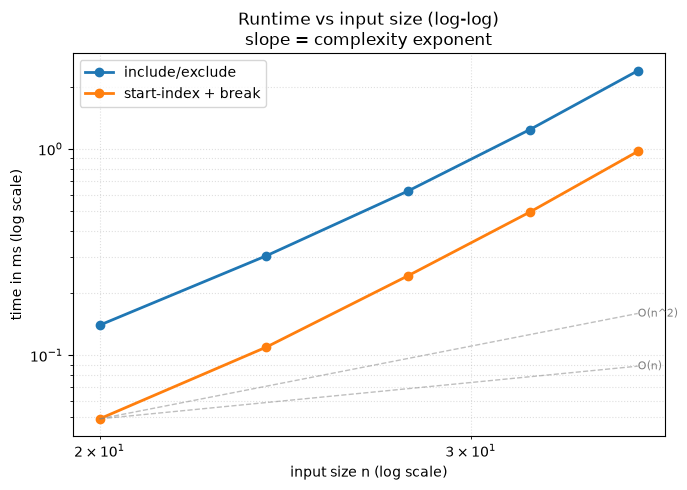

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(target):
    return (list(range(2, 12)), target)   # 10 small candidates: many ways to reach each target
solutions = {
    "include/exclude": combination_sum_include_exclude,
    "start-index + break": combination_sum_start_index,
}
sizes = [20, 24, 28, 32, 36]               # target values, +4 per step

print("answers per target:", [len(combination_sum_start_index(*make_worst_case(t))) for t in sizes])
_ = benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Combinations](README.md) — the start-index loop with reuse: recurse with `i` (not `i + 1`), and `break` once a sorted candidate exceeds the remainder.
- **Backtracking = choose / explore / undo:** `path.append` → recurse → `path.pop()`; save `path[:]`, never `path` itself.
- **Start index kills duplicate orderings:** only move forward through the candidates, so `[2, 3]` is built and `[3, 2]` never is.
- **`i` vs `i + 1` is the whole reuse rule:** `backtrack(i, ...)` allows reusing `candidates[i]`; `backtrack(i + 1, ...)` uses each element at most once (Combination Sum II).
- **Include/exclude is the same search, drawn as a binary tree:** two branches per candidate instead of a loop. It needs no sorting, but can't `break`.
- **Signal:** "find all combinations that sum to", "may be chosen an unlimited number of times", "return all unique combinations".
- **Related problems:** Combination Sum II (no reuse, duplicates in input), Combination Sum III (k numbers from 1–9), Subsets, Coin Change II (same tree, but only the **count** is asked → DP).
- **Common pitfalls:**
  1. Recursing with `i + 1` (forbids reuse) or with `0` (rebuilds `[3, 2]` after `[2, 3]`).
  2. `res.append(path)` without copying: every saved entry ends up as the same (empty) list.
  3. `continue` instead of `break` on a sorted list: still correct, just keeps checking candidates that can't fit.
  4. Forgetting `path.pop()`: choices leak into sibling branches.